In [1]:
import cv2 # opencv-python
import numpy as np
from pathlib import Path

In [2]:
import pandas as pd

In [3]:
import cv2
import numpy as np

# Rollen:
#   red    = eerste pivot (beweegt op een cirkel rond het ophangpunt)
#   green  = tweede pivot (onderkant van de tweede slinger)
#   middelpunt = geen marker meer, maar berekend met fit_circle_center()
#                uit de baan van de rode marker (zie add_center)

HSV_RANGES = {
    "red": [
        (np.array([0, 80, 50]),   np.array([10, 255, 255])),
        (np.array([170, 80, 50]), np.array([180, 255, 255])),
    ],
    "green": [
        (np.array([60, 35, 80]),  np.array([95, 255, 190])),
    ],
}

DRAW_COLORS = {
    "red":   (0, 0, 255),
    "green": (0, 255, 0),
}

COLORS = ["red", "green"]

COLUMN_NAMES = {
    "red":   "pivot1",
    "green": "pivot2",
}




def detect_color_point(frame, color, min_area=30):
    annotated = frame.copy()
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    if color not in HSV_RANGES:
        raise ValueError(f"Unknown color: {color}")

    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)
    for lower, upper in HSV_RANGES[color]:
        mask = cv2.bitwise_or(mask, cv2.inRange(hsv, lower, upper))

    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None, None, mask, annotated

    largest = max(contours, key=cv2.contourArea)
    if cv2.contourArea(largest) < min_area:
        return None, None, mask, annotated

    M = cv2.moments(largest)
    if M["m00"] == 0:
        return None, None, mask, annotated

    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])

    draw_color = DRAW_COLORS[color]
    cv2.circle(annotated, (cx, cy), 7, draw_color, -1)
    cv2.drawContours(annotated, [largest], -1, draw_color, 2)
    cv2.putText(annotated, f"{color}: ({cx}, {cy})", (cx + 10, cy - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, draw_color, 2, cv2.LINE_AA)

    return cx, cy, mask, annotated


def detect_all_points(frame):
    detections = {}
    annotated = frame.copy()

    for color in COLORS:
        x, y, mask, _ = detect_color_point(frame, color)
        detections[color] = {"x": x, "y": y, "mask": mask}

        if x is None:
            continue

        draw_color = DRAW_COLORS[color]
        cv2.circle(annotated, (x, y), 8, draw_color, -1)
        cv2.putText(annotated, f"{color}: ({x}, {y})", (x + 12, y - 12),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, draw_color, 2, cv2.LINE_AA)

    return detections, annotated

def fit_circle_center(x, y, n_iter=5, k=3.0):
    """Least-squares cirkelfit (Kåsa) met outlier-verwijdering."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    keep = ~(np.isnan(x) | np.isnan(y))

    for _ in range(n_iter):
        A = np.c_[2 * x[keep], 2 * y[keep], np.ones(keep.sum())]
        b = x[keep] ** 2 + y[keep] ** 2
        (cx, cy, c), *_ = np.linalg.lstsq(A, b, rcond=None)
        r = np.sqrt(c + cx ** 2 + cy ** 2)

        res = np.hypot(x - cx, y - cy) - r          # NaN waar detectie ontbreekt
        sigma = 1.4826 * np.nanmedian(np.abs(res[keep]))
        new = keep & (np.nan_to_num(np.abs(res), nan=np.inf) < max(k * sigma, 1.0))
        if new.sum() < 10 or new.sum() == keep.sum():
            break
        keep = new

    # Diagnostiek: hoeveel van de cirkel is daadwerkelijk doorlopen?
    ang = np.sort(np.arctan2(y[keep] - cy, x[keep] - cx))
    gaps = np.diff(np.r_[ang, ang[0] + 2 * np.pi])
    span_deg = np.degrees(2 * np.pi - gaps.max())
    rms = np.sqrt(np.mean(res[keep] ** 2))

    return {"cx": cx, "cy": cy, "r": r, "rms_px": rms,
            "span_deg": span_deg, "n_used": int(keep.sum())}


def add_center(df, source="pivot1"):
    fit = fit_circle_center(df[f"{source}_x"], df[f"{source}_y"])
    df["center_x"] = fit["cx"]
    df["center_y"] = fit["cy"]

    print(f"Middelpunt: ({fit['cx']:.1f}, {fit['cy']:.1f}) px, straal {fit['r']:.1f} px")
    print(f"Fit-fout (rms): {fit['rms_px']:.2f} px | boog: {fit['span_deg']:.0f}° | "
          f"frames gebruikt: {fit['n_used']}/{len(df)}")
    if fit["span_deg"] < 90:
        print("WAARSCHUWING: kleine boog, middelpunt onbetrouwbaar.")
    return df, fit

In [4]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd

def process_video(video_path, output_csv, preview=True, save_annotated=False):
    video_path = Path(video_path)

    if not video_path.exists():
        raise FileNotFoundError(f"Video file not found: {video_path}")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = None
    annotated_path = None

    if save_annotated:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        annotated_path = video_path.with_name(video_path.stem + "_tracked.mp4")
        writer = cv2.VideoWriter(str(annotated_path), fourcc, fps, (width, height))

    results = []
    frame_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        detections, annotated = detect_all_points(frame)
        time_s = frame_idx / fps if fps > 0 else np.nan

        row = {"frame": frame_idx, "time_s": time_s}
        for color in COLORS:
            name = COLUMN_NAMES[color]
            row[f"{name}_x"] = detections[color]["x"]
            row[f"{name}_y"] = detections[color]["y"]
        results.append(row)

        if writer is not None:
            writer.write(annotated)

        if preview:
            masks = []
            for color in COLORS:
                mask_bgr = cv2.cvtColor(detections[color]["mask"], cv2.COLOR_GRAY2BGR)
                cv2.putText(mask_bgr, color.upper(), (15, 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
                masks.append(mask_bgr)

            mask_row = np.hstack(masks)
            top = np.hstack((frame, annotated))
            mask_row = cv2.resize(mask_row, (top.shape[1], mask_row.shape[0]))
            display = cv2.resize(np.vstack((top, mask_row)), None, fx=0.5, fy=0.5)

            cv2.imshow("Double Pendulum Tracking | Original - Annotated - Masks", display)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

        frame_idx += 1

    cap.release()
    if writer is not None:
        writer.release()
    cv2.destroyAllWindows()

    df = pd.DataFrame(results)
    df.to_csv(output_csv, index=False)

    print(f"Done. Saved coordinates to: {output_csv}")
    if save_annotated:
        print(f"Saved annotated video to: {annotated_path}")
    print(f"Frames processed: {len(df)}")

    for color in COLORS:
        name = COLUMN_NAMES[color]
        missing = df[f"{name}_x"].isna().sum()
        print(f"{name} ({color}): {missing} frames with missing detection")

    return df

In [5]:
def check_lengths(df, fit, px_per_cm, L1_cm=None, L2_cm=None):
    """Controleer of de armlengtes in pixels constant zijn en vergelijk met de liniaal."""
    L1 = np.hypot(df["pivot1_x"] - fit["cx"], df["pivot1_y"] - fit["cy"])
    L2 = np.hypot(df["pivot2_x"] - df["pivot1_x"], df["pivot2_y"] - df["pivot1_y"])

    result = {}
    for name, L, ref in (("L1", L1, L1_cm), ("L2", L2, L2_cm)):
        med, sd = np.nanmedian(L), np.nanstd(L)
        line = f"{name}: {med:.1f} ± {sd:.1f} px = {med / px_per_cm:.2f} cm"
        if ref is not None:
            line += f" | liniaal: {ref:.1f} cm"
        print(line)
        result[name] = (med / px_per_cm, sd / px_per_cm)
    return result

In [6]:
video = "/Users/felixgroeneweg/Downloads/TN/RP:OP/Pendulum goede videos en code/IMG_5524.mov"
output = "20260710_141408.csv"

# 1x de video verwerken (schrijft de CSV met pivot1_* en pivot2_*)
df = process_video(
    video_path=video,
    output_csv=output,
    preview=True,
    save_annotated=True
)

# Middelpunt uit de cirkelbeweging van pivot1; voegt center_x/center_y toe
df, fit = add_center(df)
df.to_csv(output, index=False)

Done. Saved coordinates to: 20260710_141408.csv
Saved annotated video to: /Users/felixgroeneweg/Downloads/TN/RP:OP/Pendulum goede videos en code/IMG_5524_tracked.mp4
Frames processed: 258
pivot1 (red): 0 frames with missing detection
pivot2 (green): 8 frames with missing detection
Middelpunt: (975.7, 940.2) px, straal 368.9 px
Fit-fout (rms): 1.12 px | boog: 145° | frames gebruikt: 227/258


In [7]:
def export_first_frame(
    video_path,
    output_png=None,
    dpi=300
):
    """
    Export the first frame of a video as a PNG.

    The exported image keeps exactly the same pixel width and height
    as the original video frame.

    Parameters
    ----------
    video_path : str or Path
        Path to the input video.

    output_png : str or Path, optional
        Output PNG path. If None, the output name will be:
        <video_name>_first_frame.png

    dpi : float
        DPI metadata written to the PNG.
        DPI does not change the number of pixels or image quality.
    """

    video_path = Path(video_path)

    if not video_path.exists():
        raise FileNotFoundError(
            f"Video file not found: {video_path}"
        )

    if output_png is None:
        output_png = video_path.with_name(
            video_path.stem + "_first_frame.png"
        )
    else:
        output_png = Path(output_png)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    success, frame = cap.read()
    cap.release()

    if not success or frame is None:
        raise RuntimeError(
            "Could not read the first frame from the video."
        )

    height, width = frame.shape[:2]

    # OpenCV writes the original pixel data without resizing.
    success = cv2.imwrite(
        str(output_png),
        frame,
        [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )

    if not success:
        raise RuntimeError(
            f"Could not save PNG: {output_png}"
        )

    # OpenCV does not reliably write DPI metadata, so add it using Pillow.
    try:
        from PIL import Image

        with Image.open(output_png) as image:
            image.save(
                output_png,
                dpi=(dpi, dpi)
            )

    except ImportError:
        print(
            "Pillow is not installed, so DPI metadata was not added."
        )
        print(
            "Install it with: pip install pillow"
        )

    print(f"Saved first frame to: {output_png}")
    print(f"Resolution: {width} x {height} pixels")
    print(f"DPI metadata: {dpi} DPI")

    return output_png

In [8]:
PARAMS = {
    "L1": 0.210,  "dL1": 0.0005,        # m
    "L2": 0.159,  "dL2": 0.0005,        # m
    "m1": 0.6116, "dm1": 0.0005,        # kg
    "m2": 0.2074, "dm2": 0.0005,        # kg
    "px_per_m": 1784.0, "dpx_per_m": 5.0,   # 17,84 ± 0,05 px/cm
    "fps_nominal": 60.0,
    "g": 9.81,
    "pivot_px": None,                   # komt uit de cirkelfit, niet uit de screenshot
}

In [9]:
export_first_frame(
    video_path=video,
    output_png="first_frame_5524.png",
    dpi=300
)

Saved first frame to: first_frame_5524.png
Resolution: 1920 x 1080 pixels
DPI metadata: 300 DPI


PosixPath('first_frame_5524.png')


Video 1: IMG_5524.mov
Done. Saved coordinates to: tracking_5_videos/IMG_5524_tracking.csv
Frames processed: 258
pivot1 (red): 0 frames with missing detection
pivot2 (green): 8 frames with missing detection

Video 2: IMG_5525.mov
Done. Saved coordinates to: tracking_5_videos/IMG_5525_tracking.csv
Frames processed: 231
pivot1 (red): 0 frames with missing detection
pivot2 (green): 9 frames with missing detection

Video 3: IMG_5526.mov
Done. Saved coordinates to: tracking_5_videos/IMG_5526_tracking.csv
Frames processed: 257
pivot1 (red): 0 frames with missing detection
pivot2 (green): 8 frames with missing detection

Video 4: IMG_5527.mov
Done. Saved coordinates to: tracking_5_videos/IMG_5527_tracking.csv
Frames processed: 290
pivot1 (red): 0 frames with missing detection
pivot2 (green): 11 frames with missing detection

Video 5: IMG_5529.mov
Done. Saved coordinates to: tracking_5_videos/IMG_5529_tracking.csv
Frames processed: 252
pivot1 (red): 0 frames with missing detection
pivot2 (gree

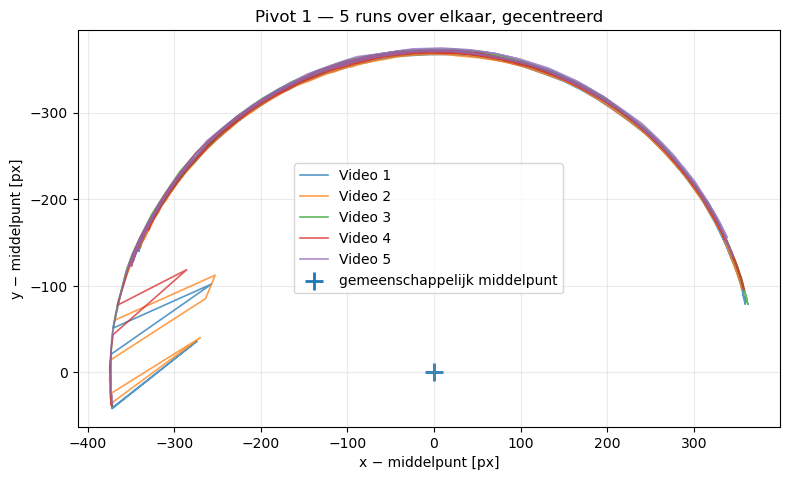

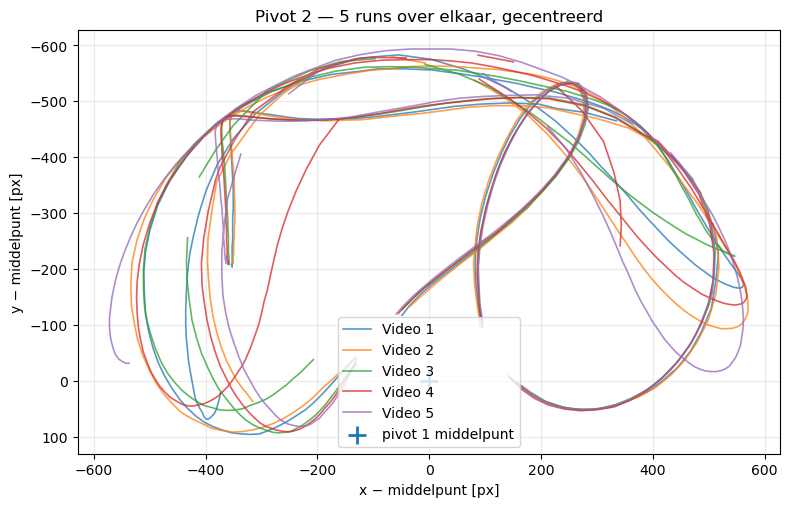

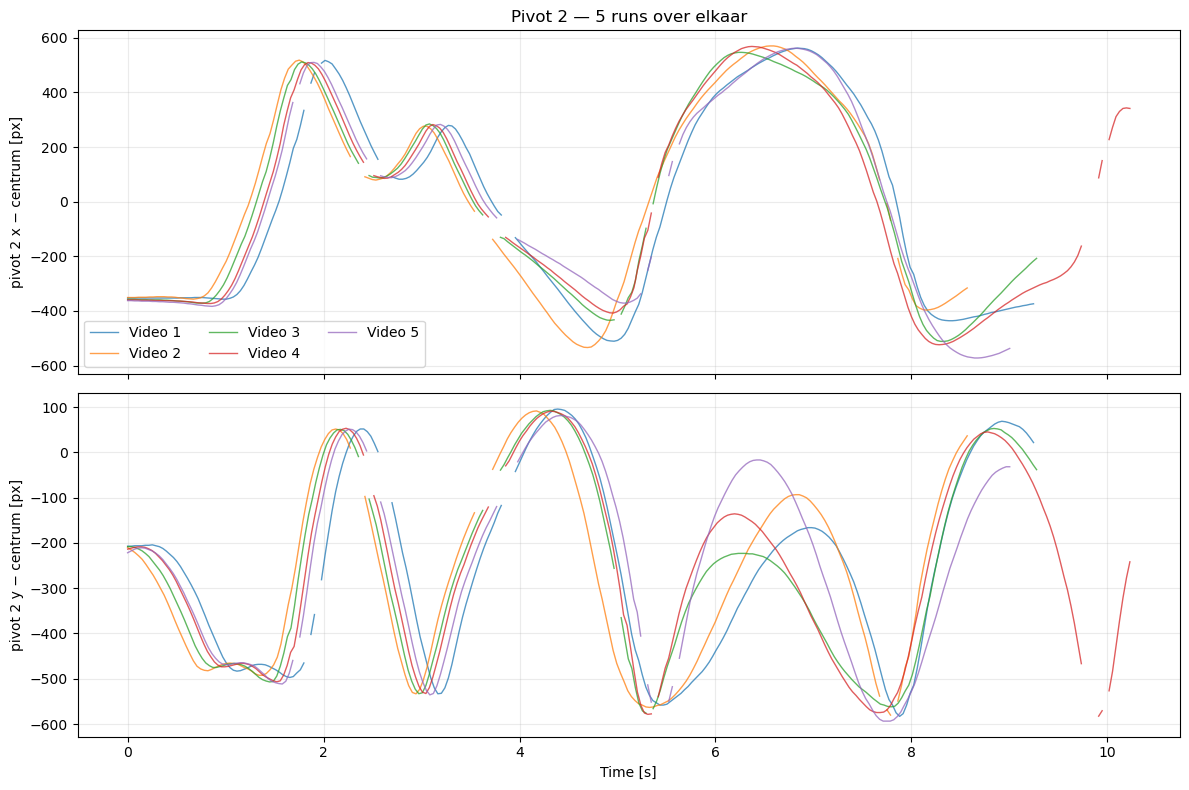


Startpunten (relatief aan het eigen middelpunt):
Video 1: pivot1=(-371.71, 39.83) px, pivot2=(-352.71, -207.17) px
Video 2: pivot1=(-372.80, 35.68) px, pivot2=(-350.80, -210.32) px
Video 3: pivot1=(-371.35, 38.94) px, pivot2=(-357.35, -208.06) px
Video 4: pivot1=(-372.62, 33.34) px, pivot2=(-359.62, -213.66) px
Video 5: pivot1=(-372.14, 25.38) px, pivot2=(-362.14, -221.62) px


In [10]:
# ============================================================
# 5 VIDEO'S VERGELIJKEN — ZONDER TRACKING-WINDOWS
# ============================================================
#
# Vul hieronder alleen de 5 videobestandsnamen/paden in.
# Bijvoorbeeld:
#   "IMG_5510.mov"
#
# De video's worden automatisch getrackt met preview=False.
# Daarna worden de banen en tijdreeksen over elkaar gelegd.
# Iedere run wordt gecentreerd op zijn eigen cirkelfit-middelpunt,
# zodat alle middelpunten exact op (0, 0) liggen in de vergelijking.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# --------- INPUT: VUL HIER JE 5 VIDEO'S IN ---------
VIDEO_FILES = [
    "IMG_5524.mov",
    "IMG_5525.mov",
    "IMG_5526.mov",
    "IMG_5527.mov",
    "IMG_5529.mov",
]

# Map waarin de CSV's met trackingdata worden opgeslagen.
CSV_DIR = Path("tracking_5_videos")
CSV_DIR.mkdir(exist_ok=True)

# True = video's opnieuw tracken.
# False = bestaande CSV gebruiken als die al bestaat.
REPROCESS = True


# --------- VIDEO'S TRACKEN / CSV'S INLEZEN ---------
runs = {}

for i, video_file in enumerate(VIDEO_FILES, start=1):
    if not video_file or not str(video_file).strip():
        continue

    video_path = Path(video_file)
    csv_path = CSV_DIR / f"{video_path.stem}_tracking.csv"
    label = f"Video {i}"

    print(f"\n{'='*60}")
    print(f"{label}: {video_path}")

    if REPROCESS or not csv_path.exists():
        # BELANGRIJK: preview=False -> GEEN tracking-window per video
        df_run = process_video(
            video_path=video_path,
            output_csv=csv_path,
            preview=False,
            save_annotated=False
        )
    else:
        print(f"Bestaande trackingdata gebruiken: {csv_path}")
        df_run = pd.read_csv(csv_path)

    # Cirkelfit van pivot 1 bepaalt het fysieke/beeld-middelpunt.
    fit_run = fit_circle_center(
        df_run["pivot1_x"],
        df_run["pivot1_y"]
    )

    # Coördinaten relatief aan het middelpunt.
    # Hierdoor ligt voor iedere run het middelpunt op exact (0, 0).
    df_run["pivot1_x_rel"] = df_run["pivot1_x"] - fit_run["cx"]
    df_run["pivot1_y_rel"] = df_run["pivot1_y"] - fit_run["cy"]
    df_run["pivot2_x_rel"] = df_run["pivot2_x"] - fit_run["cx"]
    df_run["pivot2_y_rel"] = df_run["pivot2_y"] - fit_run["cy"]

    runs[label] = {
        "video": video_path,
        "csv": csv_path,
        "df": df_run,
        "fit": fit_run,
    }

print(f"\n{len(runs)} video's geladen.")


# ============================================================
# CHECK: HOE DICHT LIGGEN DE OORSPRONKELIJKE MIDDELPUNTEN?
# ============================================================
print("\nOorspronkelijke cirkelfit-middelpunten:")
for label, run in runs.items():
    f = run["fit"]
    print(
        f"{label}: ({f['cx']:.2f}, {f['cy']:.2f}) px | "
        f"straal = {f['r']:.2f} px | "
        f"fit-RMS = {f['rms_px']:.2f} px | "
        f"boog = {f['span_deg']:.0f}°"
    )


# ============================================================
# GRAFIEK 1 — PIVOT 1 BANEN OVER ELKAAR
# Alle middelpunten liggen nu op (0, 0).
# ============================================================
plt.figure(figsize=(8, 8))

for label, run in runs.items():
    d = run["df"]
    plt.plot(
        d["pivot1_x_rel"],
        d["pivot1_y_rel"],
        alpha=0.75,
        linewidth=1.2,
        label=label
    )

plt.scatter([0], [0], marker="+", s=150, linewidths=2, label="gemeenschappelijk middelpunt")
plt.xlabel("x − middelpunt [px]")
plt.ylabel("y − middelpunt [px]")
plt.title("Pivot 1 — 5 runs over elkaar, gecentreerd")
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# GRAFIEK 2 — PIVOT 2 BANEN OVER ELKAAR
# Pivot 2 wordt met hetzelfde middelpunt gecentreerd.
# ============================================================
plt.figure(figsize=(8, 8))

for label, run in runs.items():
    d = run["df"]
    plt.plot(
        d["pivot2_x_rel"],
        d["pivot2_y_rel"],
        alpha=0.75,
        linewidth=1.2,
        label=label
    )

plt.scatter([0], [0], marker="+", s=150, linewidths=2, label="pivot 1 middelpunt")
plt.xlabel("x − middelpunt [px]")
plt.ylabel("y − middelpunt [px]")
plt.title("Pivot 2 — 5 runs over elkaar, gecentreerd")
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# GRAFIEK 3 — TIJDREEKS PIVOT 2
# Dit is de belangrijkste grafiek om de divergentie tussen
# bijna identieke starts zichtbaar te maken.
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for label, run in runs.items():
    d = run["df"]
    axes[0].plot(
        d["time_s"],
        d["pivot2_x_rel"],
        alpha=0.75,
        linewidth=1.0,
        label=label
    )
    axes[1].plot(
        d["time_s"],
        d["pivot2_y_rel"],
        alpha=0.75,
        linewidth=1.0,
        label=label
    )

axes[0].set_ylabel("pivot 2 x − centrum [px]")
axes[1].set_ylabel("pivot 2 y − centrum [px]")
axes[1].set_xlabel("Time [s]")
axes[0].set_title("Pivot 2 — 5 runs over elkaar")
axes[0].grid(True, alpha=0.25)
axes[1].grid(True, alpha=0.25)
axes[0].legend(ncol=3)
plt.tight_layout()
plt.show()


# ============================================================
# OPTIONELE CHECK — STARTPUNTEN
# Laat zien hoe dicht de vijf starts werkelijk bij elkaar liggen.
# ============================================================
print("\nStartpunten (relatief aan het eigen middelpunt):")
for label, run in runs.items():
    d = run["df"]

    first_valid = d[[
        "pivot1_x_rel", "pivot1_y_rel",
        "pivot2_x_rel", "pivot2_y_rel"
    ]].dropna().iloc[0]

    print(
        f"{label}: "
        f"pivot1=({first_valid['pivot1_x_rel']:.2f}, "
        f"{first_valid['pivot1_y_rel']:.2f}) px, "
        f"pivot2=({first_valid['pivot2_x_rel']:.2f}, "
        f"{first_valid['pivot2_y_rel']:.2f}) px"
    )


In [11]:
def measure_scale(image_path, known_length_cm, n_repeats=5, display_scale=0.5):
    """Klik per herhaling 2 punten (begin en einde van het liniaalstuk)."""
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(image_path)
    disp = cv2.resize(img, None, fx=display_scale, fy=display_scale)
    clicks = []
    win = f"Klik {n_repeats} x 2 punten (q = stoppen)"

    def on_click(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            clicks.append((x / display_scale, y / display_scale))  # terug naar originele pixels
            cv2.circle(disp, (x, y), 4, (0, 0, 255), -1)
            cv2.imshow(win, disp)

    cv2.imshow(win, disp)
    cv2.setMouseCallback(win, on_click)
    while len(clicks) < 2 * n_repeats:
        if cv2.waitKey(50) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

    n = len(clicks) // 2
    if n < 2:
        raise RuntimeError("Minstens 2 herhalingen nodig voor een onzekerheid.")
    pts = np.array(clicks[: 2 * n]).reshape(n, 2, 2)
    d_px = np.hypot(pts[:, 0, 0] - pts[:, 1, 0], pts[:, 0, 1] - pts[:, 1, 1])
    scale = d_px / known_length_cm
    print(f"Afstanden [px]: {np.round(d_px, 1)}")
    print(f"Schaal: {scale.mean():.2f} ± {scale.std(ddof=1):.2f} px/cm (n={n})")
    return scale.mean(), scale.std(ddof=1)

px_per_cm, d_px_per_cm = measure_scale(
    "/Users/felixgroeneweg/Downloads/TN/RP:OP/Pendulum goede videos en code/first_frame_5524.png", known_length_cm=50.0)   # pas de lengte aan

Afstanden [px]: [842.1 844.1 844.2 844.1   0. ]
Schaal: 13.50 ± 7.55 px/cm (n=5)


In [12]:
for label, run in runs.items():
    print(label)
    check_lengths(run["df"], run["fit"], px_per_cm=17.84, L1_cm=21.0, L2_cm=15.9)

Video 1
L1: 369.1 ± 8.4 px = 20.69 cm | liniaal: 21.0 cm
L2: 230.9 ± 8.7 px = 12.94 cm | liniaal: 15.9 cm
Video 2
L1: 368.5 ± 10.7 px = 20.65 cm | liniaal: 21.0 cm
L2: 230.0 ± 8.3 px = 12.89 cm | liniaal: 15.9 cm
Video 3
L1: 371.0 ± 1.3 px = 20.80 cm | liniaal: 21.0 cm
L2: 231.4 ± 8.0 px = 12.97 cm | liniaal: 15.9 cm
Video 4
L1: 370.1 ± 3.8 px = 20.75 cm | liniaal: 21.0 cm
L2: 231.9 ± 8.2 px = 13.00 cm | liniaal: 15.9 cm
Video 5
L1: 371.5 ± 1.3 px = 20.83 cm | liniaal: 21.0 cm
L2: 231.9 ± 8.0 px = 13.00 cm | liniaal: 15.9 cm


In [13]:
# ===== STAP 13 =====  Pixels -> meters en vaste pivot (NA de cel die `runs` maakt)

# LET OP: meet deze schaal opnieuw op een frame van DEZE serie (zie measure_scale).
PX_PER_CM = 17.84
PARAMS["px_per_m"] = PX_PER_CM * 100.0
PARAMS["dpx_per_m"] = 5.0


def fill_short_gaps(values, max_gap=5):
    """Vul gaten van NaN van hoogstens max_gap frames lineair op; langere gaten blijven NaN."""
    v = np.asarray(values, float).copy()
    isnan = np.isnan(v)
    idx = np.arange(len(v))
    start = None
    for i in range(len(v) + 1):
        cur = isnan[i] if i < len(v) else False
        if cur and start is None:
            start = i
        elif not cur and start is not None:
            end = i                                    # exclusief
            if start > 0 and (end - start) <= max_gap:
                v[start:end] = np.interp(idx[start:end], [start - 1, end], [v[start - 1], v[end]])
            start = None
    return v


def pooled_pivot(runs):
    """Eén gezamenlijke cirkelfit over de rode baan van alle runs van deze serie."""
    xs = np.concatenate([r["df"]["pivot1_x"].to_numpy(float) for r in runs.values()])
    ys = np.concatenate([r["df"]["pivot1_y"].to_numpy(float) for r in runs.values()])
    fit = fit_circle_center(xs, ys)
    print(f"Gezamenlijke pivot: ({fit['cx']:.2f}, {fit['cy']:.2f}) px | straal {fit['r']:.1f} px | "
          f"rms {fit['rms_px']:.2f} px | boog {fit['span_deg']:.0f}°")
    for label, r in runs.items():
        off = np.hypot(r["fit"]["cx"] - fit["cx"], r["fit"]["cy"] - fit["cy"])
        print(f"  {label}: eigen fit wijkt {off:.2f} px af van de gezamenlijke pivot")
    return fit


def add_metric_coords(runs, pivot, px_per_m, outlier_px=6.0, max_gap=5):
    """Voeg x1_m, y1_m, x2_m, y2_m toe: meters ten opzichte van de pivot, y positief naar BENEDEN."""
    cx, cy = pivot["cx"], pivot["cy"]
    for label, run in runs.items():
        d = run["df"]
        x1 = np.array(d["pivot1_x"], dtype=float); y1 = np.array(d["pivot1_y"], dtype=float)   # kopie
        x2 = np.array(d["pivot2_x"], dtype=float); y2 = np.array(d["pivot2_y"], dtype=float)

        # Foute rode detecties (bijv. hand): afstand tot de pivot wijkt te veel af van de mediaan
        L1 = np.hypot(x1 - cx, y1 - cy)
        bad = np.abs(L1 - np.nanmedian(L1)) > outlier_px
        x1[bad] = np.nan; y1[bad] = np.nan
        x2[bad] = np.nan; y2[bad] = np.nan      # arm 2 hangt aan arm 1: ook onbetrouwbaar

        x1, y1, x2, y2 = (fill_short_gaps(a, max_gap) for a in (x1, y1, x2, y2))

        d["x1_m"] = (x1 - cx) / px_per_m
        d["y1_m"] = (y1 - cy) / px_per_m
        d["x2_m"] = (x2 - cx) / px_per_m
        d["y2_m"] = (y2 - cy) / px_per_m
        print(f"{label}: {int(bad.sum())} rode uitschieters verwijderd | "
              f"NaN over: rood {int(np.isnan(x1).sum())}, groen {int(np.isnan(x2).sum())} van {len(d)} frames")


pivot = pooled_pivot(runs)
PARAMS["pivot_px"] = (pivot["cx"], pivot["cy"])
add_metric_coords(runs, pivot, PARAMS["px_per_m"])

Gezamenlijke pivot: (975.65, 941.43) px | straal 370.2 px | rms 1.29 px | boog 174°
  Video 1: eigen fit wijkt 1.26 px af van de gezamenlijke pivot
  Video 2: eigen fit wijkt 2.11 px af van de gezamenlijke pivot
  Video 3: eigen fit wijkt 0.95 px af van de gezamenlijke pivot
  Video 4: eigen fit wijkt 0.23 px af van de gezamenlijke pivot
  Video 5: eigen fit wijkt 2.25 px af van de gezamenlijke pivot
Video 1: 2 rode uitschieters verwijderd | NaN over: rood 0, groen 0 van 258 frames
Video 2: 3 rode uitschieters verwijderd | NaN over: rood 0, groen 0 van 231 frames
Video 3: 0 rode uitschieters verwijderd | NaN over: rood 0, groen 0 van 257 frames
Video 4: 1 rode uitschieters verwijderd | NaN over: rood 0, groen 0 van 290 frames
Video 5: 0 rode uitschieters verwijderd | NaN over: rood 0, groen 0 van 252 frames


In [14]:
# ===== STAP 14 =====  Absolute hoeken theta1 en theta2
# Conventie: theta = 0 als de arm recht naar BENEDEN hangt, positief richting rechts in het beeld.
# theta1 = hoek van pivot -> rood, theta2 = hoek van rood -> groen (beide ten opzichte van de verticaal).

def unwrap_nan(a):
    """np.unwrap die NaN's overslaat."""
    a = np.asarray(a, float)
    out = np.full_like(a, np.nan)
    ok = ~np.isnan(a)
    out[ok] = np.unwrap(a[ok])
    return out


def add_angles(runs, jump_warn_rad=0.5):
    for label, run in runs.items():
        d = run["df"]
        th1 = np.arctan2(d["x1_m"].to_numpy(float), d["y1_m"].to_numpy(float))
        th2 = np.arctan2((d["x2_m"] - d["x1_m"]).to_numpy(float),
                         (d["y2_m"] - d["y1_m"]).to_numpy(float))
        d["theta1"] = unwrap_nan(th1)
        d["theta2"] = unwrap_nan(th2)

        j1 = np.nanmax(np.abs(np.diff(d["theta1"])))
        j2 = np.nanmax(np.abs(np.diff(d["theta2"])))
        flag = "  <-- CONTROLEER" if max(j1, j2) > jump_warn_rad else ""
        print(f"{label}: grootste hoeksprong per frame: theta1 {j1:.3f} rad, theta2 {j2:.3f} rad{flag}")


add_angles(runs)

Video 1: grootste hoeksprong per frame: theta1 0.097 rad, theta2 0.263 rad
Video 2: grootste hoeksprong per frame: theta1 0.099 rad, theta2 0.296 rad
Video 3: grootste hoeksprong per frame: theta1 0.099 rad, theta2 0.316 rad
Video 4: grootste hoeksprong per frame: theta1 0.101 rad, theta2 0.312 rad
Video 5: grootste hoeksprong per frame: theta1 0.100 rad, theta2 0.299 rad


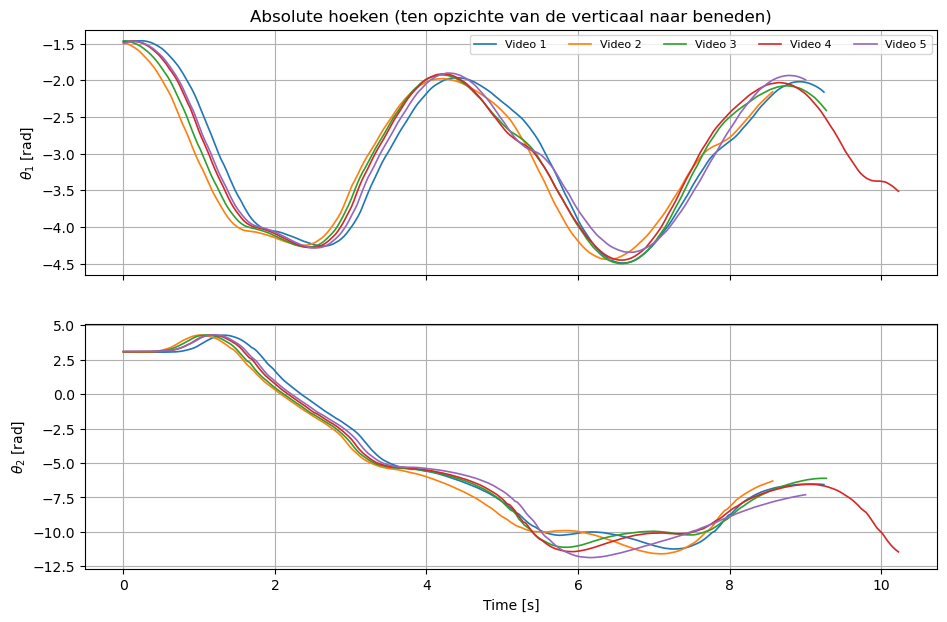

In [15]:
# ===== STAP 15 =====  Plot de hoeken voordat je differentieert
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for label, run in runs.items():
    d = run["df"]
    ax[0].plot(d["time_s"], d["theta1"], lw=1.2, label=label)
    ax[1].plot(d["time_s"], d["theta2"], lw=1.2, label=label)
ax[0].set_ylabel(r"$\theta_1$ [rad]")
ax[1].set_ylabel(r"$\theta_2$ [rad]")
ax[1].set_xlabel("Time [s]")
ax[0].set_title("Absolute hoeken (ten opzichte van de verticaal naar beneden)")
for a in ax:
    a.grid(True)
plt.show()